<a href="https://colab.research.google.com/github/paocamacho06-jpg/Simulacion-ll/blob/main/Movimiento_Browniano_precio_de_las_acciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

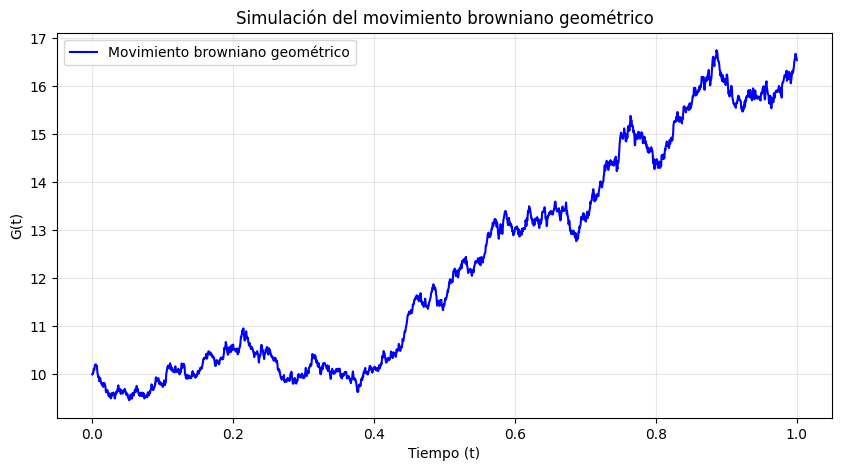

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Parámetros
G0 = 10
mu = 0.1
sigma = 0.2
T = 1
n = 2000

# Discretización del tiempo
dt = T/n
t = np.linspace(0, T, n+1)

# Movimiento browniano estándar
np.random.seed(42)
Z = np.random.normal(0, 1, n)
B = np.concatenate(([0], np.cumsum(np.sqrt(dt)*Z)))

# Movimiento browniano con deriva
X = mu*t + sigma*B

# Movimiento browniano geométrico
G = G0*np.exp(X)

# Gráfica
plt.figure(figsize=(10, 5))
plt.plot(t, G, color="blue",
         label="Movimiento browniano geométrico")

plt.xlabel("Tiempo (t)")
plt.ylabel("G(t)")
plt.title("Simulación del movimiento browniano geométrico")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


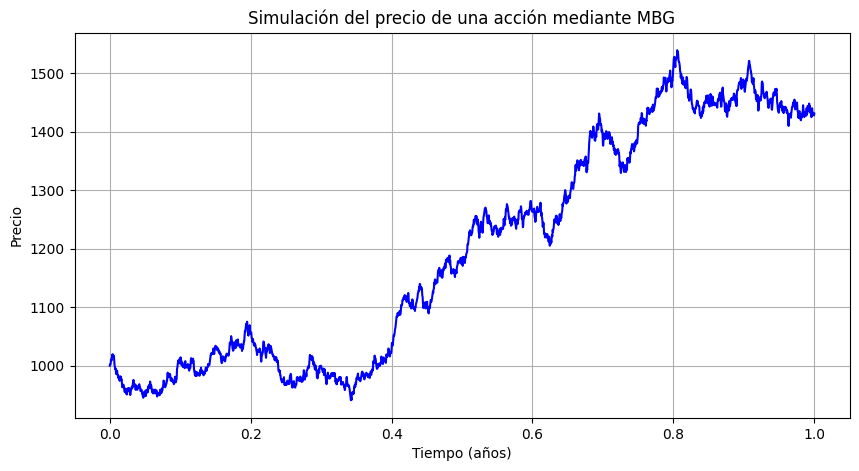

In [20]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Parámetros
P0 = 1000
mu = 0.05
sigma = 0.20
T = 1
n = 2200

dt = T / n
t = np.linspace(0, T, n + 1)

# Función del movimiento browniano geométrico
def movimiento_geometrico(P0, mu, sigma, T, n):
    dt = T / n
    Z = np.random.normal(0, 1, n)
    W = np.concatenate(([0], np.cumsum(np.sqrt(dt) * Z)))

    P = P0 * np.exp((mu - sigma**2 / 2) * t + sigma * W)
    return P

# Simulación
P = movimiento_geometrico(P0, mu, sigma, T, n)

plt.figure(figsize=(10, 5))
plt.plot(t, P, color="blue")
plt.title("Simulación del precio de una acción mediante MBG")
plt.xlabel("Tiempo (años)")
plt.ylabel("Precio")
plt.grid(True)
plt.show()


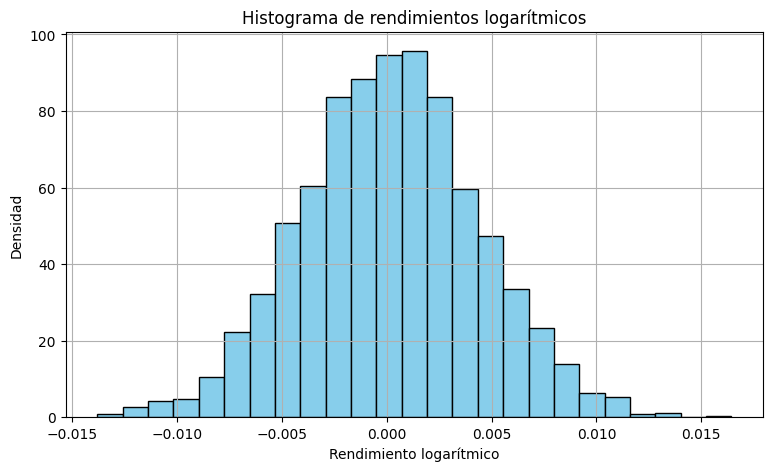

In [21]:
# Rendimientos logarítmicos
R = np.log(P[1:] / P[:-1])

plt.figure(figsize=(9, 5))
plt.hist(R, bins=25, density=True,
         color="skyblue", edgecolor="black")

plt.title("Histograma de rendimientos logarítmicos")
plt.xlabel("Rendimiento logarítmico")
plt.ylabel("Densidad")
plt.grid(True)
plt.show()


In [24]:
import pandas as pd
import numpy as np

# Calcular rendimientos logarítmicos
R = np.log(P[1:] / P[:-1])

# Crear una serie de tiempo sin t=0
serie_R = pd.Series(
    R,
    index=np.arange(1, len(P)),
    name="Rendimientos"
)

print(serie_R)

1       0.002132
2      -0.000576
3       0.002775
4       0.006508
5      -0.000985
          ...   
2196   -0.002809
2197    0.001830
2198    0.000095
2199   -0.002722
2200    0.002094
Name: Rendimientos, Length: 2200, dtype: float64


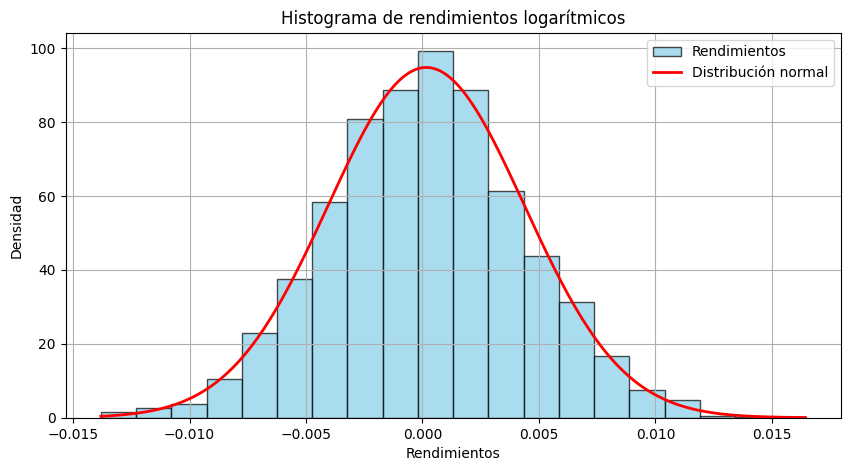

In [26]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

# Datos de la serie de rendimientos
R = serie_R.values

# Media y desviación estándar
media = np.mean(R)
desviacion = np.std(R, ddof=1)

# Histograma
plt.figure(figsize=(10, 5))

plt.hist(R, bins=20, density=True,
         color="skyblue", edgecolor="black",
         alpha=0.7, label="Rendimientos")

# Curva normal
x = np.linspace(min(R), max(R), 200)
y = norm.pdf(x, media, desviacion)

plt.plot(x, y, color="red", linewidth=2,
         label="Distribución normal")

plt.title("Histograma de rendimientos logarítmicos")
plt.xlabel("Rendimientos")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.show()
